# Seidel Diagram

The Seidel diagram shows how much of each third-order aberration every surface contributes. `optic.aberrations.seidels()` gives the five Seidel sums for the whole system; the diagram splits them into the contribution of each surface, so you can see which surfaces create an aberration and which ones cancel it.

In [1]:
from optiland.analysis import SeidelDiagram
from optiland.samples.objectives import CookeTriplet

In [2]:
lens = CookeTriplet()

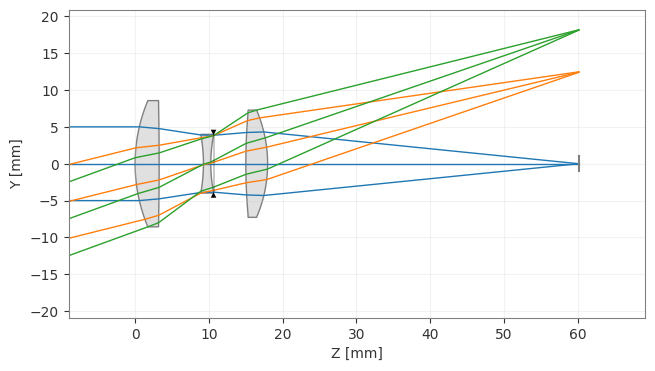

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [3]:
lens.draw()

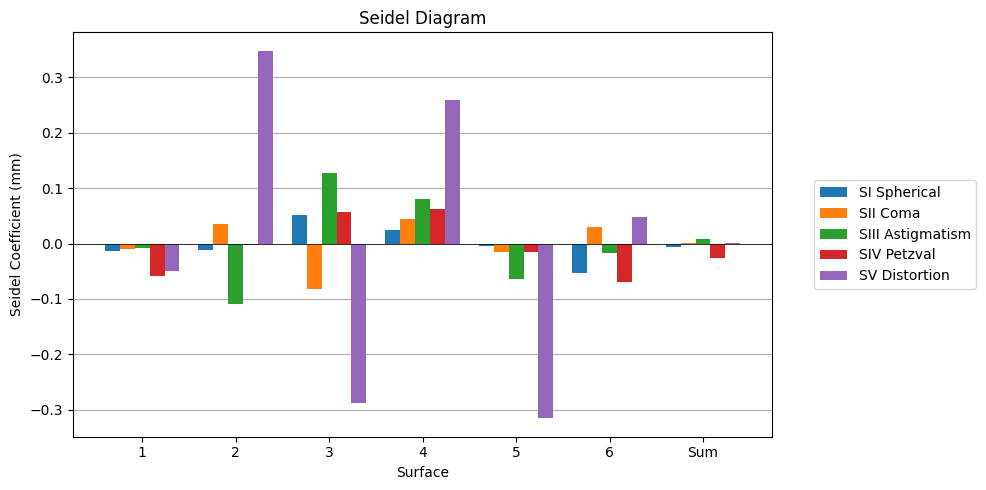

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Seidel Diagram'}, xlabel='Surface', ylabel='Seidel Coefficient (mm)'>)

In [4]:
seidel = SeidelDiagram(lens)
seidel.view()

How to read the plot:

- Each group of bars is one surface, labelled with its surface index. The object and image surfaces contribute nothing and are not shown.
- Each color is one Seidel coefficient: SI spherical aberration, SII coma, SIII astigmatism, SIV Petzval field curvature and SV distortion. The coefficients are wavefront Seidel sums in lens units, evaluated at the primary wavelength.
- The last group, `Sum`, is the total over all surfaces. It equals `lens.aberrations.seidels()`.
- Bars of opposite sign on different surfaces cancel. Large contributions that cancel in the sum point to surfaces that are sensitive to manufacturing and alignment errors.

In this triplet, the negative middle lens (surfaces 3 and 4) adds positive Petzval terms that offset the negative ones of the two outer lenses, which flattens the field. Single surfaces contribute up to 0.35 mm of distortion, yet the sum is close to zero.

The numbers behind the plot are in `seidel.data`: `"per_surface"` holds one row per Seidel coefficient and one column per surface, and `"sum"` holds the totals. They are also available directly from `lens.aberrations.seidels_per_surface()`.

In [5]:
print(seidel.data["per_surface"].shape)
print(seidel.data["sum"])

(5, 6)
[-0.00696026  0.00123489  0.00890661 -0.02571584  0.00185882]
